# E4: calibrated Whisper + acoustic fusion SVM probabilities

Add sigmoid probability calibration to the selected **Fusion SVM** from
`E4_02_whisper_svm_concatenate.ipynb`. Keep its 65 acoustic columns, Whisper
embeddings, PCA dimensions, group weights, and selected SVM settings fixed.

Use five speaker-separated folds on **training plus validation** to obtain
held-out decision scores for calibration. Refit the entire fusion pipeline on
development data; scaling and PCA are fitted separately inside every fold.
Test clips stay out of fitting. **Run All includes test evaluation.**

Predict Singapore (`1`) when `p_singapore >= 0.50`; otherwise Non-Singapore (`0`).
Compare with the original fusion model's zero-threshold decisions. Report balanced
accuracy, recall, false positives/negatives, Brier score, log loss, ROC AUC, and
a probability reliability plot. Save a separate calibrated model and reports.

This is exploratory: development labels helped select acoustic features and
fusion C, and these test speakers were evaluated before. Sources and prompts
differ between classes. High probability does not detect unfamiliar audio or
establish calibration on a different population. No test-based tuning is done here.

## 1. Settings and saved inputs

Run the E1 91-feature study and `E4_02_whisper_svm_concatenate.ipynb` first.
This notebook reuses their saved splits, acoustic cache, Whisper cache, model,
and provenance; it does not decode audio, download Whisper, or extract embeddings.
The saved Whisper cache must remain available. Run from the project folder, or
set `PROJECT_ROOT` below. Use the scikit-learn version that saved the E4 model.

In [1]:
# Install into your notebook environment if necessary, then restart the kernel:
# %pip install numpy pandas scikit-learn matplotlib joblib
from pathlib import Path
import hashlib
import json
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (balanced_accuracy_score, brier_score_loss,
    confusion_matrix, log_loss, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_ROOT = Path.cwd().resolve()
E1_DIR = PROJECT_ROOT / 'outputs/e1_feature_study_accent_30000'
E4_DIR = PROJECT_ROOT / 'outputs/svm65_fusion_comparison_30000'
RESULTS_DIR = E4_DIR / 'calibrated_probability_testing'
SOURCE_MODEL_PATH = E4_DIR / 'fusion_svm.joblib'
RANDOM_SEED = 42
CV_FOLDS = 5
THRESHOLD = 0.50  # Fixed before inspecting test probabilities.


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text())


required_paths = [SOURCE_MODEL_PATH, E4_DIR / 'model_metadata.json',
    E4_DIR / 'dataset_identity.json', E4_DIR / 'speaker_splits.csv',
    E1_DIR / 'speaker_splits.csv', E1_DIR / 'current_cache_metadata.json',
    E1_DIR / 'acoustic_features_91.npz']
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError('Run the E1 and E4 studies first. Missing: ' + ', '.join(missing))
source_hashes = {path: file_hash(path) for path in required_paths}
model_metadata = read_json(E4_DIR / 'model_metadata.json')
if sklearn.__version__ != model_metadata['versions']['sklearn']:
    raise RuntimeError('Use the original model scikit-learn version: '
                       + model_metadata['versions']['sklearn'])
if model_metadata['positive_label'] != 1 or model_metadata['probability_calibration']:
    raise ValueError('Expected the original, uncalibrated fusion model with Singapore as class 1.')

string_columns = ['clip_id', 'speaker_group', 'split', 'source',
                  'source_clip_id', 'speaker_id', 'accent_group']
snapshot_options = dict(index_col='clip_id', keep_default_na=False,
                        dtype={column: str for column in string_columns})
snapshot = pd.read_csv(E4_DIR / 'speaker_splits.csv', **snapshot_options)
if not snapshot.equals(pd.read_csv(E1_DIR / 'speaker_splits.csv', **snapshot_options)):
    raise ValueError('E4 and E1 saved splits differ.')
if snapshot.empty or not snapshot.index.is_unique or snapshot.isna().any().any():
    raise ValueError('Invalid saved split.')
if set(snapshot['split']) != {'train', 'validation', 'test'}:
    raise ValueError('Expected train, validation, and test splits.')
if (snapshot.groupby('speaker_group')['split'].nunique() > 1).any():
    raise ValueError('Speaker overlap between splits.')
if (snapshot.groupby('speaker_group')['label'].nunique() > 1).any():
    raise ValueError('A speaker has mixed labels.')
dataset_id = digest(snapshot.reset_index().to_dict(orient='records'))
identity = read_json(E4_DIR / 'dataset_identity.json')
base_metadata = read_json(E1_DIR / 'current_cache_metadata.json')
if not (dataset_id == identity['dataset_id'] == model_metadata['dataset_id']
        == base_metadata['dataset_id']):
    raise ValueError('Saved dataset identities differ.')
if digest(base_metadata['audio']) != identity['audio_id']:
    raise ValueError('Saved audio identities differ.')

clip_ids = snapshot.index.to_numpy(dtype=str)
y = snapshot['label'].to_numpy(dtype=np.int64)
groups = snapshot['speaker_group'].to_numpy(dtype=str)
indices = {name: np.flatnonzero(snapshot['split'].eq(name))
           for name in ('train', 'validation', 'test')}
for name, rows in indices.items():
    if set(y[rows]) != {0, 1}:
        raise ValueError(f'Both classes must occur in {name}.')
# Preserve the original final-fitting order: train first, then validation.
development_idx = np.concatenate([indices['train'], indices['validation']])
test_idx = indices['test']
print('scikit-learn:', sklearn.__version__)
print('Development clips:', len(development_idx), '| test clips:', len(test_idx))

scikit-learn: 1.9.1
Development clips: 25500 | test clips: 4500


## 2. Reconstruct the original fusion inputs

The model expects **raw selected 65 acoustic values followed by raw Whisper
embeddings**, not PCA-transformed features. With the saved Whisper base model,
this is 65 + 512 = 577 input columns; the pipeline produces 65 + 32 = 97 columns
for its SVM. Check cache identities, clip order, feature order, and model settings.

In [2]:
acoustic_info = model_metadata['acoustic_provenance']
columns = model_metadata['feature_columns_in_91']
if (len(columns) != 65 or len(set(columns)) != 65
        or any(type(i) is not int or not 0 <= i < 91 for i in columns)
        or columns != acoustic_info['feature_columns']):
    raise ValueError('Invalid saved acoustic feature columns.')
with np.load(E1_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    X91 = cache['features'].copy()
    feature_names = cache['feature_names'].tolist()
    acoustic_cache_id = str(cache['cache_id'].item())
    for key, expected in [('clip_ids', clip_ids), ('labels', y), ('groups', groups)]:
        if not np.array_equal(cache[key], expected):
            raise ValueError(f'Acoustic cache {key} differ from the saved split.')
expected_cache_id = digest({'base_cache_id': digest(base_metadata),
    'clip_ids': clip_ids.tolist(), 'delta_width': 9, 'delta_version': 1})
if (acoustic_cache_id != expected_cache_id or acoustic_cache_id != acoustic_info['cache_id']
        or X91.shape != (len(clip_ids), 91) or not np.isfinite(X91).all()):
    raise ValueError('Invalid acoustic cache identity or matrix.')
if (model_metadata['feature_names'] != [feature_names[i] for i in columns]
        or model_metadata['feature_names'] != acoustic_info['feature_names']):
    raise ValueError('Acoustic feature order differs.')

whisper_info = model_metadata['whisper_provenance']
whisper_settings = {key: whisper_info[key] for key in
    ('dataset_id', 'audio_id', 'model', 'revision', 'pooling', 'sample_rate')}
whisper_cache_id = digest(whisper_settings)
whisper_path = E4_DIR / 'feature_cache' / f'whisper_{whisper_cache_id}.npz'
if not whisper_path.is_file():
    raise FileNotFoundError(f'Run E4 to prepare the saved Whisper cache: {whisper_path}')
source_hashes[whisper_path] = file_hash(whisper_path)
if (whisper_cache_id != whisper_info['cache_id'] or whisper_info['dataset_id'] != dataset_id
        or whisper_info['audio_id'] != identity['audio_id']
        or whisper_info['model'] != model_metadata['whisper_model']
        or whisper_info['revision'] != model_metadata['whisper_revision']):
    raise ValueError('Whisper provenance differs from the model or dataset.')
with np.load(whisper_path, allow_pickle=False) as cache:
    W = cache['features'].copy()
    if (str(cache['cache_id'].item()) != whisper_cache_id
            or json.loads(str(cache['provenance_json'].item())) != whisper_info):
        raise ValueError('Whisper cache provenance differs.')
    for key, expected in [('clip_ids', clip_ids), ('labels', y), ('groups', groups)]:
        if not np.array_equal(cache[key], expected):
            raise ValueError(f'Whisper cache {key} differ from the saved split.')
if (W.shape != (len(clip_ids), model_metadata['whisper_width'])
        or whisper_info['width'] != W.shape[1] or not np.isfinite(W).all()):
    raise ValueError('Invalid Whisper embedding matrix.')

# Match E4's float32 acoustic conversion and concatenation exactly.
A = X91[:, columns].astype(np.float32)
X_fusion = np.column_stack((A, W))
original_model = joblib.load(SOURCE_MODEL_PATH)
if list(original_model.classes_) != [0, 1] or original_model.n_features_in_ != X_fusion.shape[1]:
    raise ValueError('Original model classes or input width differ.')
preprocess = original_model.named_steps['preprocess']
fitted_pca = preprocess.named_transformers_['whisper'].named_steps['pca']
if (original_model.named_steps['classifier'].C != model_metadata['chosen_C']['Fusion SVM']
        or fitted_pca.n_components_ != model_metadata['whisper_pca_dimensions']):
    raise ValueError('Original model settings differ from metadata.')
if (list(preprocess.transformers_[0][2]) != list(range(65))
        or list(preprocess.transformers_[1][2]) != list(range(65, X_fusion.shape[1]))):
    raise ValueError('Original preprocessing column order differs.')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Fusion input:', X_fusion.shape, '| selected C:', model_metadata['chosen_C']['Fusion SVM'])
print('Whisper cache:', whisper_path.name)
print('Outputs:', RESULTS_DIR)

Fusion input: (30000, 577) | selected C: 10.0
Whisper cache: whisper_451ecfaef0c9cf1df62937d9cf2a199f76d19696954afa017649deee7fa6d790.npz
Outputs: /home/mh/nusproj/E1_Feature_EngineeringV2/outputs/svm65_fusion_comparison_30000/calibrated_probability_testing


## 3. Prepare speaker-separated calibration folds

Every development clip supplies one held-out decision score. Keep speakers
separate and both classes on each side of every fold. The test split is excluded.

In [3]:
splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
folds = list(splitter.split(X_fusion[development_idx], y[development_idx], groups[development_idx]))
held_counts = np.zeros(len(development_idx), dtype=int)
fold_rows = []
for fold, (fit, held) in enumerate(folds, start=1):
    fit_rows, held_rows = development_idx[fit], development_idx[held]
    if set(groups[fit_rows]) & set(groups[held_rows]):
        raise ValueError('Speaker overlap inside a calibration fold.')
    if set(np.r_[fit_rows, held_rows]) & set(test_idx):
        raise ValueError('Test clips entered calibration.')
    if set(y[fit_rows]) != {0, 1} or set(y[held_rows]) != {0, 1}:
        raise ValueError('Both classes must occur on both sides of every fold.')
    held_counts[held] += 1
    fold_rows.append({'fold': fold, 'fit_clips': len(fit), 'held_clips': len(held),
        'fit_speakers': len(set(groups[fit_rows])), 'held_speakers': len(set(groups[held_rows]))})
if not np.all(held_counts == 1):
    raise ValueError('Every development clip must be held out exactly once.')
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
fold_summary.to_csv(RESULTS_DIR / 'calibration_folds.csv', index=False)

,fold,fit_clips,held_clips,fit_speakers,held_speakers
0,1,20400,5100,5849,1462
1,2,20400,5100,5849,1462
2,3,20400,5100,5849,1462
3,4,20399,5101,5848,1463
4,5,20401,5099,5849,1462


## 4. Calibrate and save a separate model

`ensemble=False` fits one sigmoid from held-out development scores and refits
one fusion pipeline on all development clips. Cloning the **whole pipeline**
ensures acoustic scaling, Whisper scaling, PCA, and component scaling are fitted
inside each fold. No feature selection, C search, or threshold search is repeated.

Verify that the refitted pipeline reproduces the original raw decision scores
before saving the calibrated model. These score checks do not fit or tune anything.
Original E1/E4 files remain unchanged. PCA can depend on numerical-library and
thread settings; use the original numerical environment for this strict score check.

In [4]:
started = perf_counter()
calibrated_model = CalibratedClassifierCV(
    estimator=clone(original_model), method='sigmoid', cv=folds, ensemble=False, n_jobs=1,
)
calibrated_model.fit(X_fusion[development_idx], y[development_idx])
refitted_model = calibrated_model.calibrated_classifiers_[0].estimator
maximum_difference = 0.0
for first in range(0, len(X_fusion), 1000):
    batch = X_fusion[first:first + 1000]
    original_scores = original_model.decision_function(batch)
    refitted_scores = refitted_model.decision_function(batch)
    np.testing.assert_allclose(refitted_scores, original_scores, rtol=1e-8, atol=1e-8,
        err_msg='Refit differs: verify original inputs and NumPy/BLAS thread settings.')
    maximum_difference = max(maximum_difference, float(np.max(np.abs(refitted_scores - original_scores))))

probability_metadata = {
    'source_notebook': 'E4_02_whisper_svm_concatenate.ipynb',
    'source_model': str(SOURCE_MODEL_PATH.relative_to(PROJECT_ROOT)),
    'source_sha256': source_hashes[SOURCE_MODEL_PATH],
    'dataset_id': dataset_id, 'audio_id': identity['audio_id'],
    'acoustic_cache_id': acoustic_cache_id, 'whisper_cache_id': whisper_cache_id,
    'acoustic_source_feature_count': 91, 'acoustic_feature_count': 65,
    'acoustic_columns_in_91': columns, 'acoustic_feature_names': model_metadata['feature_names'],
    'whisper_width': int(W.shape[1]), 'input_feature_count': int(X_fusion.shape[1]),
    'fusion_input': model_metadata['fusion_input'],
    'whisper_pca_dimensions': model_metadata['whisper_pca_dimensions'],
    'chosen_C': model_metadata['chosen_C']['Fusion SVM'],
    'whisper_provenance': whisper_info, 'acoustic_provenance': acoustic_info,
    'calibration': 'sigmoid', 'ensemble': False, 'folds': CV_FOLDS,
    'speaker_grouped': True, 'random_seed': RANDOM_SEED,
    'fit_split': 'train_plus_validation', 'threshold': THRESHOLD, 'positive_label': 1,
    'decision_rule': 'Singapore (1) if p_singapore >= 0.50; otherwise Non-Singapore (0)',
    'fixed_feature_selection': True, 'fixed_hyperparameters': True,
    'purpose': 'exploratory_probability_testing',
    'maximum_original_score_difference': maximum_difference,
    'sklearn_version': sklearn.__version__,
}
calibrated_model.e4_probability_metadata_ = probability_metadata
CALIBRATED_PATH = RESULTS_DIR / 'fusion_svm_calibrated.joblib'
joblib.dump(calibrated_model, CALIBRATED_PATH)
(RESULTS_DIR / 'fusion_svm_calibrated_metadata.json').write_text(
    json.dumps(probability_metadata, indent=2) + '\n')
print(f'Calibrated and saved in {perf_counter() - started:.1f}s')
print('Maximum original decision-score difference:', maximum_difference)

Calibrated and saved in 68.5s
Maximum original decision-score difference: 0.0


## 5. Read clip probabilities

The helper takes a **91-column acoustic matrix** and the corresponding **raw
Whisper embeddings** in the same row order, selects the saved 65 columns, and
returns probabilities plus the class at threshold 0.50. It does not extract features.
Use the same acoustic feature definitions and Whisper model, revision, and pooling
as the saved provenance. At exactly 0.50 the helper chooses class 1; scikit-learn
`predict()` chooses class 0.

In [5]:
def predict_clip_probabilities(acoustic_features_91, whisper_embeddings, model):
    acoustic = np.asarray(acoustic_features_91)
    whisper = np.asarray(whisper_embeddings)
    info = model.e4_probability_metadata_
    if (acoustic.ndim != 2 or acoustic.shape[1] != info['acoustic_source_feature_count']
            or not np.isfinite(acoustic).all()):
        raise ValueError('Expected a finite 91-column acoustic feature matrix.')
    if (whisper.ndim != 2 or whisper.shape != (len(acoustic), info['whisper_width'])
            or not np.isfinite(whisper).all()):
        raise ValueError('Expected finite Whisper embeddings with matching rows and saved width.')
    selected = acoustic[:, info['acoustic_columns_in_91']].astype(np.float32)
    inputs = np.column_stack((selected, whisper))
    probabilities = model.predict_proba(inputs)
    classes = list(model.classes_)
    p_singapore = probabilities[:, classes.index(1)]
    p_non_singapore = probabilities[:, classes.index(0)]
    predicted = (p_singapore >= info['threshold']).astype(int)
    return pd.DataFrame({'predicted_class': predicted, 'p_singapore': p_singapore,
        'p_non_singapore': p_non_singapore,
        'predicted_class_probability': np.where(predicted == 1, p_singapore, p_non_singapore)})


# For later use: load this artifact and run the helper with matching source features.
model = joblib.load(CALIBRATED_PATH)
display(predict_clip_probabilities(X91[test_idx[:5]], W[test_idx[:5]], model).round(4))
# Direct API (input is selected raw acoustic values + raw Whisper embeddings):
# fused = np.column_stack((X91_new[:, model.e4_probability_metadata_['acoustic_columns_in_91']]
#                          .astype(np.float32), W_new))
# probabilities = model.predict_proba(fused)  # Columns correspond to model.classes_.

,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0,1.0,1.0
1,0,0.0,1.0,1.0
2,0,0.0,1.0,1.0
3,0,0.0,1.0,1.0
4,0,0.0,1.0,1.0


## 6. Evaluate test classes and probability quality

Compare original and calibrated decisions on the same saved test clips. Lower
Brier score and log loss are better; higher balanced accuracy and ROC AUC are
better. The original uncalibrated SVM has no probability metrics.

The reliability curve compares mean predicted Singapore probability with the
observed Singapore fraction in ten equal-count bins. The diagonal is ideal.
The histogram shows where the probabilities fall. These are descriptive test
checks; do not select a threshold or calibration method from these results.

,system,balanced_accuracy,singapore_recall,non_singapore_false_positive_rate,false_positive,false_negative,errors,roc_auc,brier_score,log_loss
0,Original fusion SVM,0.9847,0.9929,0.0236,53,16,69,0.9989,NaN,NaN
1,Calibrated fusion SVM at 0.50,0.9847,0.9884,0.0191,43,26,69,0.9989,0.0114,0.0417


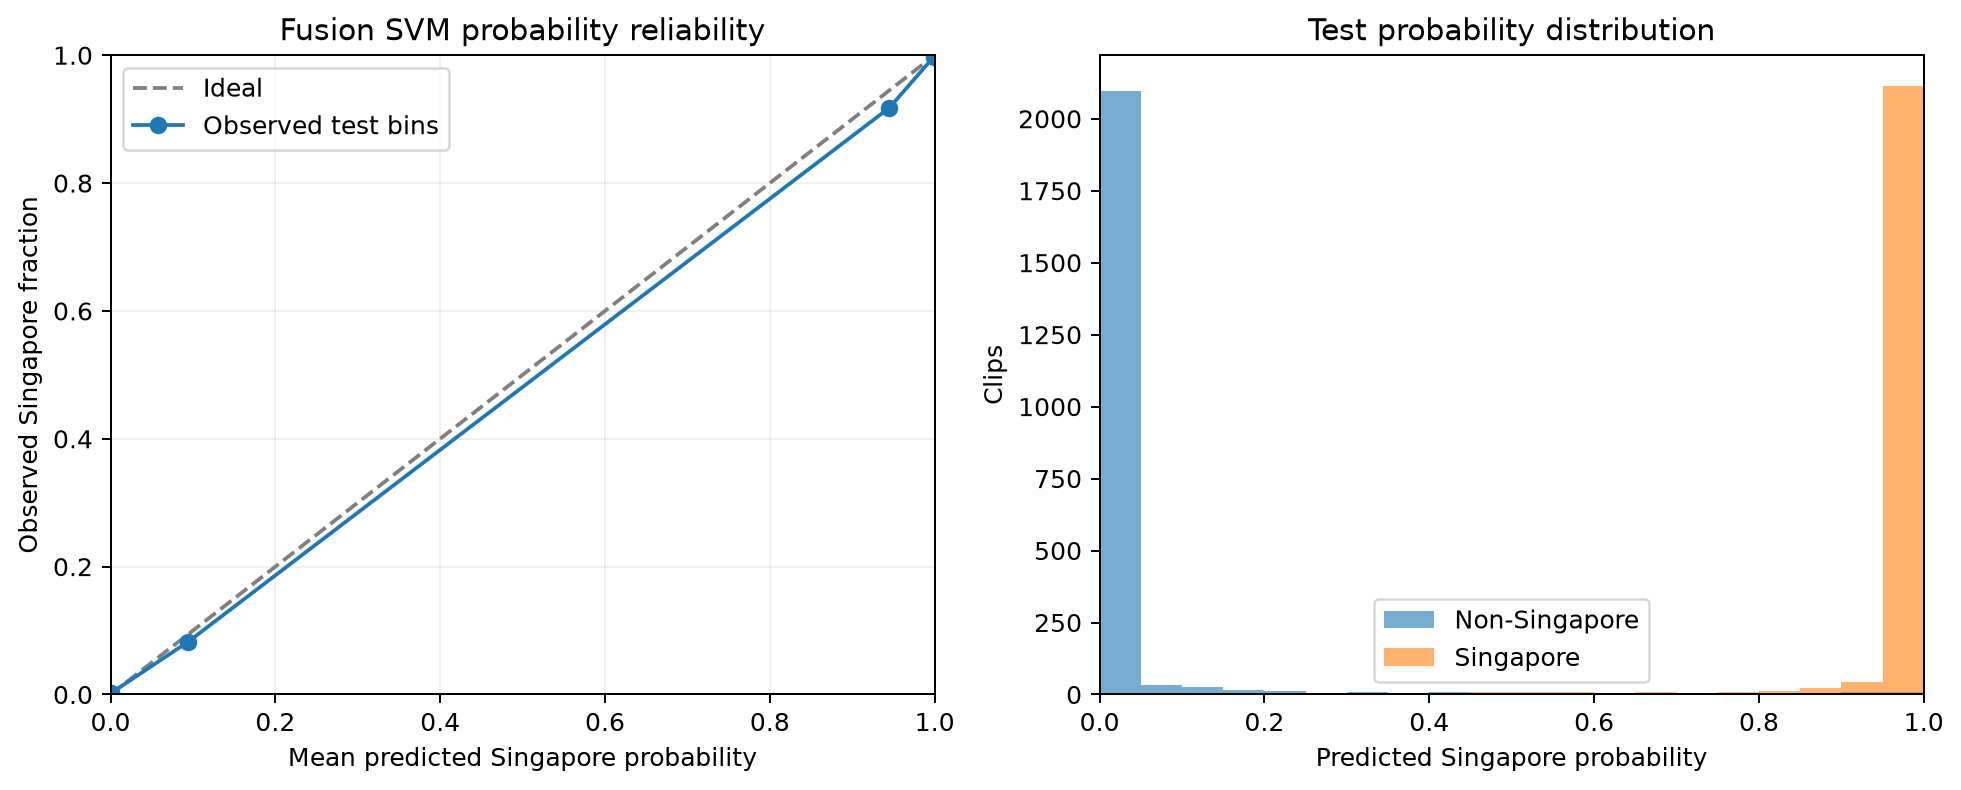

In [6]:
test_predictions = predict_clip_probabilities(X91[test_idx], W[test_idx], model)
for position, (name, values) in enumerate([
    ('clip_id', clip_ids[test_idx]), ('speaker_group', groups[test_idx]),
    ('source', snapshot.iloc[test_idx]['source'].to_numpy()), ('true_label', y[test_idx])]):
    test_predictions.insert(position, name, values)
raw_prediction = original_model.predict(X_fusion[test_idx])
raw_scores = original_model.decision_function(X_fusion[test_idx])
test_predictions['original_svm_prediction'] = raw_prediction
test_predictions['original_decision_score'] = raw_scores

# If E4's saved predictions are available, verify the reconstructed inputs reproduce them.
upstream_path = E4_DIR / 'test_predictions.csv'
if upstream_path.is_file():
    upstream = pd.read_csv(upstream_path, keep_default_na=False, dtype={'clip_id': str})
    upstream = upstream.loc[upstream['model'].eq('Fusion SVM')].set_index('clip_id')
    if not upstream.index.is_unique or set(upstream.index) != set(clip_ids[test_idx]):
        raise ValueError('E4 fusion test clip IDs differ.')
    upstream = upstream.loc[clip_ids[test_idx]]
    np.testing.assert_array_equal(upstream['true_label'], y[test_idx])
    np.testing.assert_array_equal(upstream['prediction'], raw_prediction)
    np.testing.assert_allclose(upstream['decision_score'], raw_scores, rtol=1e-8, atol=1e-8)

score_rows = []
for name, prediction, scores, is_calibrated in [
    ('Original fusion SVM', raw_prediction, raw_scores, False),
    ('Calibrated fusion SVM at 0.50', test_predictions['predicted_class'],
     test_predictions['p_singapore'], True)]:
    tn, fp, fn, tp = confusion_matrix(y[test_idx], prediction, labels=[0, 1]).ravel()
    score_rows.append({'system': name,
        'balanced_accuracy': balanced_accuracy_score(y[test_idx], prediction),
        'singapore_recall': tp / (tp + fn),
        'non_singapore_false_positive_rate': fp / (tn + fp),
        'false_positive': int(fp), 'false_negative': int(fn), 'errors': int(fp + fn),
        'roc_auc': roc_auc_score(y[test_idx], scores),
        'brier_score': brier_score_loss(y[test_idx], scores) if is_calibrated else np.nan,
        'log_loss': log_loss(y[test_idx], test_predictions[['p_non_singapore', 'p_singapore']],
                             labels=[0, 1]) if is_calibrated else np.nan})
test_summary = pd.DataFrame(score_rows)
display(test_summary.round(4))

fraction, mean_probability = calibration_curve(
    y[test_idx], test_predictions['p_singapore'], n_bins=10, strategy='quantile')
reliability_bins = pd.DataFrame({'mean_p_singapore': mean_probability,
                                'observed_singapore_fraction': fraction})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
axes[0].plot(mean_probability, fraction, 'o-', label='Observed test bins')
axes[0].set(title='Fusion SVM probability reliability', xlim=(0, 1), ylim=(0, 1),
    xlabel='Mean predicted Singapore probability', ylabel='Observed Singapore fraction')
axes[0].legend()
axes[0].grid(alpha=.2)
for label, title in [(0, 'Non-Singapore'), (1, 'Singapore')]:
    axes[1].hist(test_predictions.loc[test_predictions['true_label'].eq(label), 'p_singapore'],
                 bins=np.linspace(0, 1, 21), alpha=.6, label=title)
axes[1].set(title='Test probability distribution', xlabel='Predicted Singapore probability',
            ylabel='Clips', xlim=(0, 1))
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'test_probability_reliability.png', dpi=180, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(RESULTS_DIR / 'test_probability_reliability.png')))
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
test_predictions.to_csv(RESULTS_DIR / 'test_probability_predictions.csv', index=False)
reliability_bins.to_csv(RESULTS_DIR / 'test_reliability_bins.csv', index=False)

## 7. Check the saved artifact and original files

Check probability bounds, row sums, persistence, helper input validation, and
class consistency away from an exact 0.50 tie. Verify the original model, metadata,
split snapshots, and feature caches have not changed.

In [7]:
reloaded = joblib.load(CALIBRATED_PATH)
reloaded_rows = predict_clip_probabilities(X91[test_idx], W[test_idx], reloaded)
in_memory_rows = predict_clip_probabilities(X91[test_idx], W[test_idx], calibrated_model)
pd.testing.assert_frame_equal(reloaded_rows, in_memory_rows)
probabilities = reloaded_rows[['p_non_singapore', 'p_singapore']].to_numpy()
assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1.0)
direct = reloaded.predict(X_fusion[test_idx])
not_tie = reloaded_rows['p_singapore'].to_numpy() != THRESHOLD
np.testing.assert_array_equal(direct[not_tie], reloaded_rows['predicted_class'].to_numpy()[not_tie])
for acoustic, whisper in [(X91[:2, :90], W[:2]), (X91[:2], W[:1]),
                           (X91[:2], np.full_like(W[:2], np.nan))]:
    try:
        predict_clip_probabilities(acoustic, whisper, reloaded)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid feature inputs were accepted.')
assert reloaded.e4_probability_metadata_ == read_json(RESULTS_DIR / 'fusion_svm_calibrated_metadata.json')
for path, original_hash in source_hashes.items():
    assert file_hash(path) == original_hash, f'Original file changed: {path}'
print('Saved fusion model: probability, class, persistence, and input checks passed.')
print('Original model, metadata, splits, and feature caches are unchanged.')
print('Calibrated model, metadata, fold summary, test CSVs, and chart:', RESULTS_DIR)

Saved fusion model: probability, class, persistence, and input checks passed.
Original model, metadata, splits, and feature caches are unchanged.
Calibrated model, metadata, fold summary, test CSVs, and chart: /home/mh/nusproj/E1_Feature_EngineeringV2/outputs/svm65_fusion_comparison_30000/calibrated_probability_testing
